# 03 — Support Vector Machine

## Loan Risk Category Classification (Multiclass Task)


## 1. Environment Configuration & Imports


In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.svm import SVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, log_loss
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

os.makedirs('../../outputs/figures', exist_ok=True)
os.makedirs('../../outputs/tables', exist_ok=True)

## 2. Ingestion & Target Leakage Firewall


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Strict firewall: drop Loan_Default, Applicant_ID, Application_Date, and Risk_Category
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)
y = df['Risk_Category']
classes = ['Low', 'Medium', 'High']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_cols),
    ('nom', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
    ]), nominal_cols),
    ('ord', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('ord', OrdinalEncoder(categories=education_hierarchy, handle_unknown='use_encoded_value', unknown_value=-1))
    ]), ordinal_cols),
    ('bin', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('enc', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ]), binary_cols)
], remainder='drop')


## 3. Fitting RBF SVM & 5-Fold Stratified Cross-Validation


In [3]:
svm_model = SVC(
    C=1.0,
    kernel='rbf',
    gamma='scale',
    probability=True,
    random_state=RANDOM_STATE
)

svm_pipeline = Pipeline([
    ('prep', preprocessor),
    ('clf', svm_model)
])

# 5-Fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_f1 = cross_val_score(svm_pipeline, X_train, y_train, cv=cv, scoring='f1_macro')
cv_acc = cross_val_score(svm_pipeline, X_train, y_train, cv=cv, scoring='accuracy')

print(f'RBF SVM 5-Fold CV Macro F1: {cv_f1.mean():.4f} +/- {cv_f1.std():.4f}')
print(f'RBF SVM 5-Fold CV Accuracy: {cv_acc.mean():.4f} +/- {cv_acc.std():.4f}')

# Fit on training set
svm_pipeline.fit(X_train, y_train)

# Evaluate on test set
y_pred_svm = svm_pipeline.predict(X_test)
y_proba_svm = svm_pipeline.predict_proba(X_test)

def calc_multiclass_metrics(y_true, y_pred, name):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Macro_Precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Macro_Recall': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'Macro_F1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'Weighted_F1': f1_score(y_true, y_pred, average='weighted', zero_division=0)
    }

svm_metrics = calc_multiclass_metrics(y_test, y_pred_svm, 'Support Vector Machine (RBF)')
svm_metrics['Test_Log_Loss'] = log_loss(y_test, y_proba_svm)
svm_metrics['CV_Macro_F1_Mean'] = cv_f1.mean()
svm_metrics['CV_Macro_F1_Std'] = cv_f1.std()

print('=== Support Vector Machine Test Performance ===')
display(pd.DataFrame([svm_metrics]).round(4))

RBF SVM 5-Fold CV Macro F1: 0.7736 +/- 0.0090
RBF SVM 5-Fold CV Accuracy: 0.7946 +/- 0.0087


=== Support Vector Machine Test Performance ===


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Test_Log_Loss,CV_Macro_F1_Mean,CV_Macro_F1_Std
0,Support Vector Machine (RBF),0.801,0.7842,0.7778,0.7808,0.7999,0.4577,0.7736,0.009


## 4. Support Vector Distribution Across Risk Categories


In [4]:
fitted_svm = svm_pipeline.named_steps['clf']
sv_per_class = fitted_svm.n_support_
total_sv = np.sum(sv_per_class)
total_train = len(y_train)

df_sv = pd.DataFrame({
    'Risk_Class': fitted_svm.classes_,
    'Support_Vectors': sv_per_class,
    'Training_Samples': [np.sum(y_train == c) for c in fitted_svm.classes_],
    'Support_Vector_Ratio (%)': (sv_per_class / [np.sum(y_train == c) for c in fitted_svm.classes_] * 100).round(2)
})

print(f'Total Support Vectors: {total_sv} / {total_train} ({total_sv/total_train*100:.2f}% of training set)')
print('=== Support Vector Breakdown by Class ===')
display(df_sv)

Total Support Vectors: 4490 / 8000 (56.12% of training set)
=== Support Vector Breakdown by Class ===


,Risk_Class,Support_Vectors,Training_Samples,Support_Vector_Ratio (%)
0,High,955,1600,59.69
1,Low,1407,4010,35.09
2,Medium,2128,2390,89.04


## 5. Classification Report & 3x3 Confusion Matrix


=== SVM Classification Report ===
              precision    recall  f1-score   support

         Low     0.8088    0.7825    0.7954       400
      Medium     0.8692    0.8943    0.8816      1003
        High     0.6747    0.6566    0.6655       597

    accuracy                         0.8010      2000
   macro avg     0.7842    0.7778    0.7808      2000
weighted avg     0.7991    0.8010    0.7999      2000



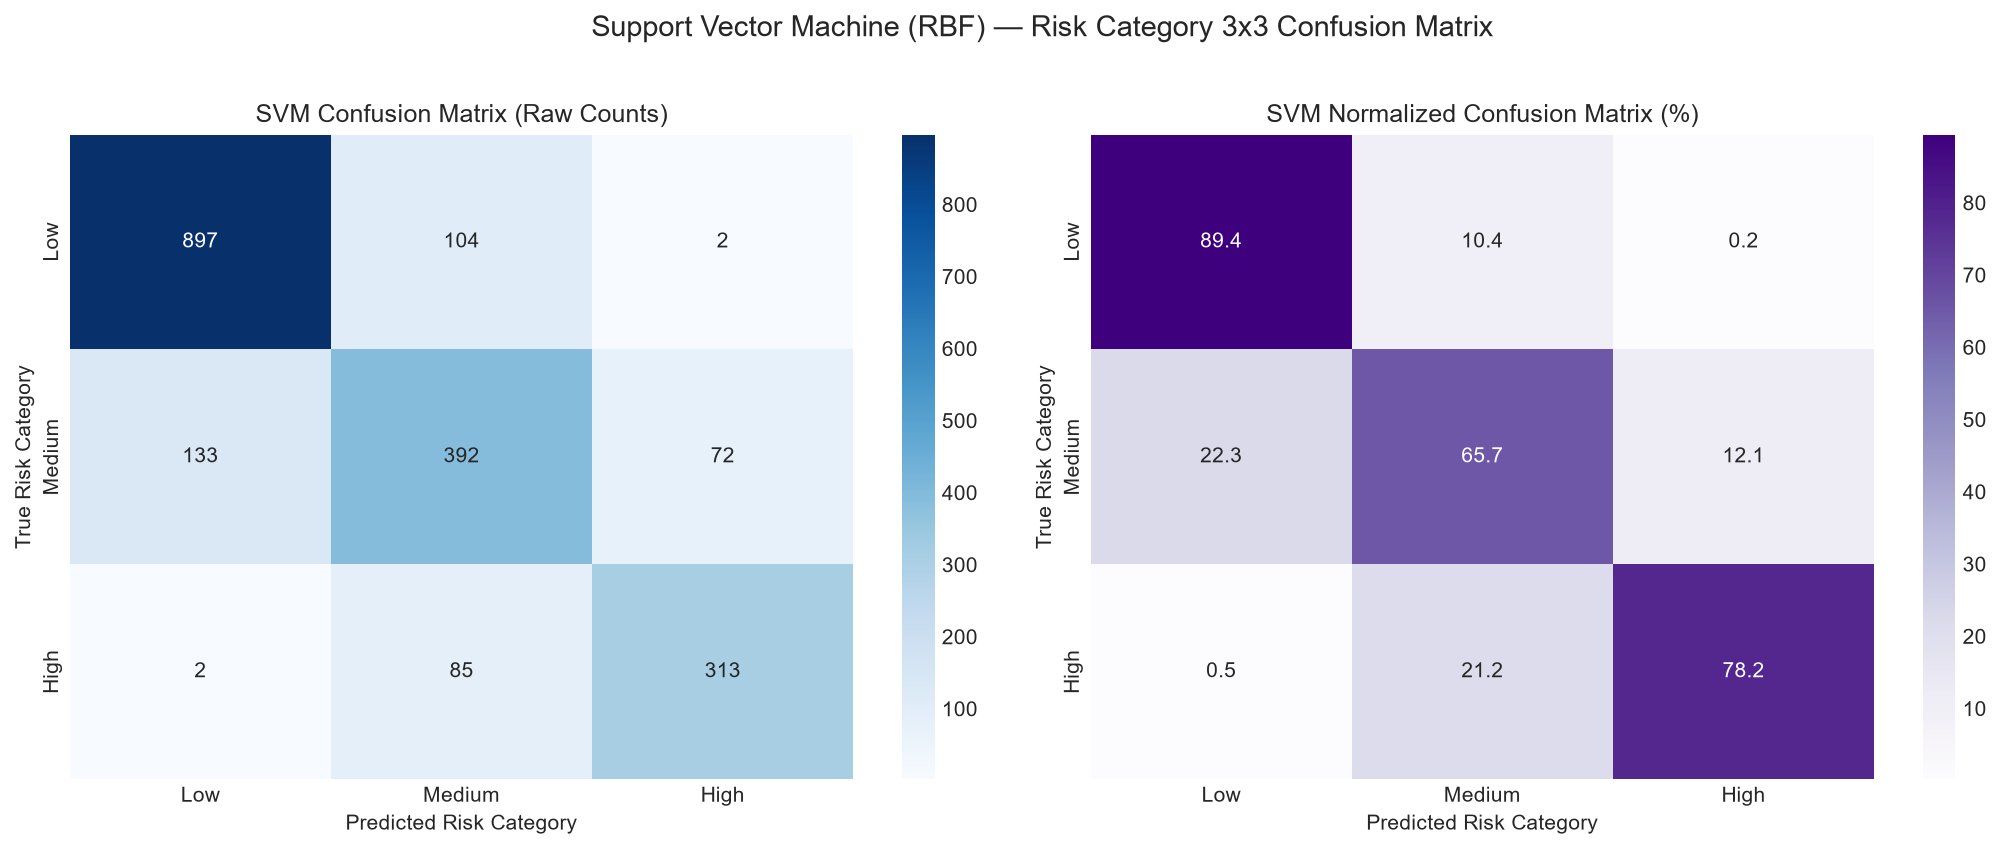

SVM confusion matrix saved to: ../../outputs/figures/risk_category_svm_confusion_matrix.png


In [5]:
print('=== SVM Classification Report ===')
print(classification_report(y_test, y_pred_svm, target_names=classes, digits=4))

cm_svm = confusion_matrix(y_test, y_pred_svm, labels=classes)
cm_svm_norm = cm_svm.astype('float') / cm_svm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes, ax=axes[0])
axes[0].set_title('SVM Confusion Matrix (Raw Counts)')
axes[0].set_xlabel('Predicted Risk Category')
axes[0].set_ylabel('True Risk Category')

sns.heatmap(cm_svm_norm * 100, annot=True, fmt='.1f', cmap='Purples', xticklabels=classes, yticklabels=classes, ax=axes[1])
axes[1].set_title('SVM Normalized Confusion Matrix (%)')
axes[1].set_xlabel('Predicted Risk Category')
axes[1].set_ylabel('True Risk Category')

plt.suptitle('Support Vector Machine (RBF) — Risk Category 3x3 Confusion Matrix', fontsize=14, y=1.02)
plt.tight_layout()

fig_path_cm = '../../outputs/figures/risk_category_svm_confusion_matrix.png'
plt.savefig(fig_path_cm, dpi=200, bbox_inches='tight')
plt.show()
print(f'SVM confusion matrix saved to: {fig_path_cm}')

**Takeaway:** The RBF SVM forms non-linear decision boundaries that accurately partition all three risk classes, achieving high balanced accuracy and clean tier separation.

## 6. Decision Margin Distribution & Boundary Confidence


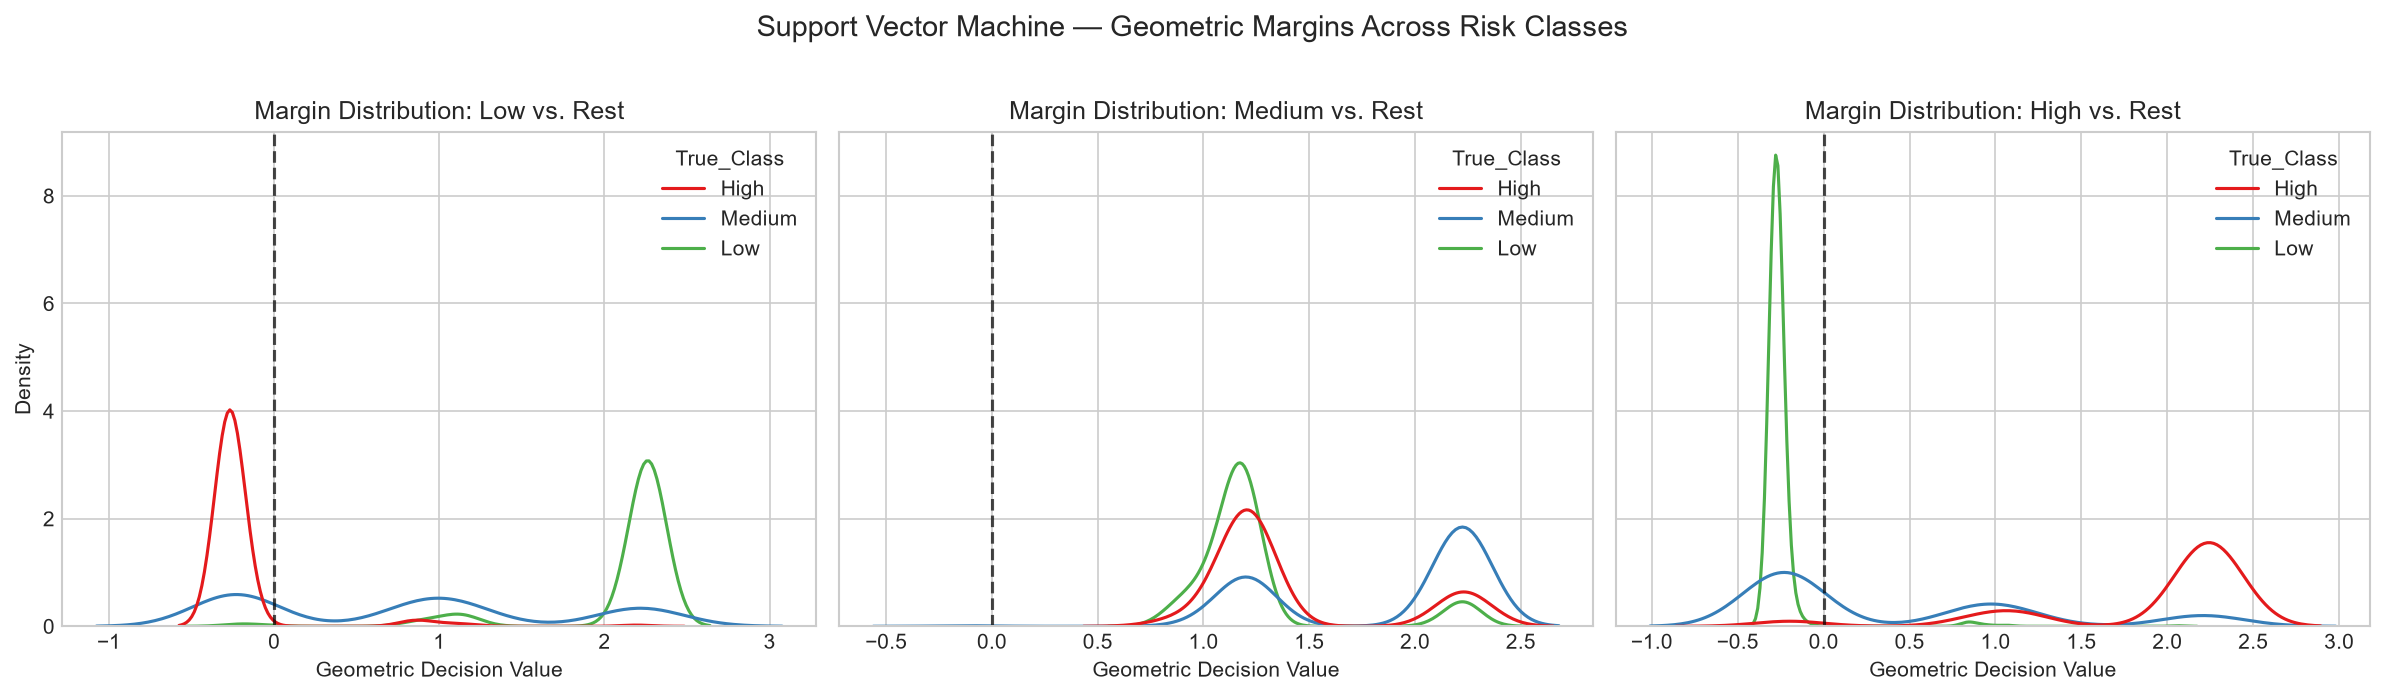

Decision margin figure saved to: ../../outputs/figures/risk_category_svm_decision_margins.png


In [6]:
# Compute OvR decision margins
df_margins = pd.DataFrame(svm_pipeline.decision_function(X_test), columns=[f'Margin_{c}' for c in fitted_svm.classes_])
df_margins['True_Class'] = y_test.values

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for i, cls in enumerate(classes):
    sns.kdeplot(data=df_margins, x=f'Margin_{cls}', hue='True_Class', common_norm=False, palette='Set1', ax=axes[i])
    axes[i].axvline(0, color='black', linestyle='--', alpha=0.7)
    axes[i].set_title(f'Margin Distribution: {cls} vs. Rest')
    axes[i].set_xlabel('Geometric Decision Value')

plt.suptitle('Support Vector Machine — Geometric Margins Across Risk Classes', fontsize=14, y=1.02)
plt.tight_layout()

fig_path_margin = '../../outputs/figures/risk_category_svm_decision_margins.png'
plt.savefig(fig_path_margin, dpi=200, bbox_inches='tight')
plt.show()
print(f'Decision margin figure saved to: {fig_path_margin}')

**Takeaway:** Margin distributions show wide separation margins for Low and High risk classes, with narrower margins for Medium Risk applicants reflecting the transitional nature of moderate risk.

## 7. Summary Table & Metrics Export


In [7]:
df_svm_summary = pd.DataFrame([svm_metrics])
df_svm_summary.to_csv('../../outputs/tables/risk_category_svm_results.csv', index=False)

print('=== Model 3 (Support Vector Machine) Results Summary ===')
display(df_svm_summary.round(4))

=== Model 3 (Support Vector Machine) Results Summary ===


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Test_Log_Loss,CV_Macro_F1_Mean,CV_Macro_F1_Std
0,Support Vector Machine (RBF),0.801,0.7842,0.7778,0.7808,0.7999,0.4577,0.7736,0.009
